In [1]:
import pickle
from one.api import ONE
import pandas as pd
import SimpleITK as sitk
from brainwidemap import bwm_query, load_good_units, load_trials_and_mask, bwm_units

In [2]:
with open("all_units.pkl", "rb") as f:
    all_units = pickle.load(f)

all_units

[{'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 2,
  'x': -0.002289,
  'y': -0.002537,
  'z': -0.003595,
  'atlas_id': 549,
  'spike_times': array([1280.17956115, 1308.40397292, 1408.93956308, ..., 4687.2943644 ,
         4688.31736358, 4688.35463022]),
  'spike_voltage': array([7.00786186e-05, 7.97781831e-05, 7.22701807e-05, ...,
         8.15545573e-05, 7.05181228e-05, 7.70979532e-05])},
 {'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 15,
  'x': -0.002289,
  'y': -0.002533,
  'z': -0.003576,
  'atlas_id': 549,
  'spike_times': array([   7.27930925,   10.02560684,   10.05437348, ..., 4688.53469674,
         4688.60163002, 4688.63716332]),
  'spike_voltage': array([0.00033245, 0.00033308, 0.00031968, ..., 0.00031284, 0.00034012,
         0.00033704])},
 {'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 22,
  'x': -0.002289,
  'y': -0.002528,
  'z': -0.003556,
  'atlas_id': 549,
  'spike_times': array([ 219.74047516,  556.91181808,  593.60

In [3]:
len(all_units)

75708

In [4]:
#one = ONE(base_url='https://openalyx.internationalbrainlab.org',password='international', mode='remote')
#unit_df = bwm_units(one)
#unit_df.to_csv('unit_df.csv', index=False) 
unit_df = pd.read_csv('unit_df.csv')
unit_df

,Beryl,eid,channels,depths,uuids,cluster_id,amp_max,amp_min,amp_median,amp_std_dB,...,ks2_label,x,y,z,acronym,atlas_id,axial_um,lateral_um,pid,spike_count_good
0,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,61,620.0,c5cabbda-1f74-4168-ad5e-7c5a2f533d9f,79,0.000300,0.000081,0.000158,1.056608,...,good,-0.002378,-0.000250,-0.006350,CNU,23,620.0,11.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,167762.0
1,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,68,700.0,5b5176f2-228f-46b5-85c8-205cf9d90a53,88,0.000323,0.000123,0.000221,0.972567,...,good,-0.002364,-0.000250,-0.006272,CNU,23,700.0,43.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,16139.0
2,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,71,720.0,19930b44-2f8a-44e1-a8ce-46184f7334cb,91,0.000187,0.000057,0.000109,1.266665,...,good,-0.002364,-0.000250,-0.006252,CNU,23,720.0,27.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,34700.0
3,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,77,780.0,304c2251-f207-4926-ba28-967ebbda4473,105,0.000208,0.000046,0.000079,1.655816,...,good,-0.002364,-0.000250,-0.006192,CNU,23,780.0,11.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,224475.0
4,AAA,37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0,82,840.0,4bd714b8-5753-4561-87e5-2ef3126426b7,115,0.000346,0.000085,0.000163,1.334542,...,good,-0.002364,-0.000250,-0.006132,CNU,23,840.0,59.0,f4ff3ff8-19b7-40c7-bf6f-8b577b811ed1,292062.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62985,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,55,560.0,3beabe91-423a-49c3-8e55-fb846457c89d,152,0.000258,0.000093,0.000139,1.890024,...,good,-0.001714,-0.006287,-0.004645,HB,765,560.0,27.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,2307.0
62986,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,57,580.0,78952ffb-d419-464e-96e9-2b22723aa58b,158,0.000910,0.000085,0.000170,3.049439,...,good,-0.001725,-0.006281,-0.004621,HB,765,580.0,11.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,544566.0
62987,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,54,560.0,2490ff61-baae-4e8e-a90e-d34e851b8cd1,160,0.000213,0.000069,0.000119,1.654493,...,good,-0.001714,-0.006287,-0.004645,HB,765,560.0,59.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,37240.0
62988,x,810b1e07-009e-4ebe-930a-915e4cd8ece4,58,600.0,945e9b3b-0a09-4272-b56e-7640e1e1f647,161,0.000247,0.000070,0.000109,1.398105,...,good,-0.001735,-0.006276,-0.004598,HB,765,600.0,59.0,c5fd185f-1c5a-4aad-9795-43c4ccf8ea94,37519.0


In [5]:
len(unit_df['eid'].unique())

454

In [6]:
from iblatlas.regions import BrainRegions
import pandas as pd

br = BrainRegions()

region_table = pd.DataFrame({
    'atlas_id': br.id,
    'acronym': br.acronym,
    'name': br.name,
    'level': br.level,
    'parent': br.parent,
    'order': br.order
})

region_table[:]

,atlas_id,acronym,name,level,parent,order
0,0,void,void,0,NaN,0
1,997,root,root,0,NaN,0
2,8,grey,Basic cell groups and regions,1,997.0,1
3,567,CH,Cerebrum,2,8.0,2
4,688,CTX,Cerebral cortex,3,567.0,3
...,...,...,...,...,...,...
2650,-49,ipf,intraparafloccular fissure (left),3,-1040.0,1322
2651,-57,pms,paramedian sulcus (left),3,-1040.0,1323
2652,-65,pfs,parafloccular sulcus (left),3,-1040.0,1324
2653,-624,IPF,Interpeduncular fossa (left),2,-1024.0,1325


In [7]:
region_table[region_table["level"]==5]

,atlas_id,acronym,name,level,parent,order
6,315,Isocortex,Isocortex,5,695.0,5
380,698,OLF,Olfactory areas,5,695.0,379
455,1089,HPF,Hippocampal formation,5,695.0,454
557,16,6b,Layer 6b isocortex,5,703.0,556
558,583,CLA,Claustrum,5,703.0,557
...,...,...,...,...,...,...
2614,-595,fr,fasciculus retroflexus (left),5,-1083.0,1286
2615,-611,hbc,habenular commissure (left),5,-1083.0,1287
2616,-730,PIS,pineal stalk (left),5,-1083.0,1288
2618,-547,dlf,dorsal longitudinal fascicle (left),5,-70.0,1290


In [8]:
atlas_id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
atlas_id_to_acronym

{0: 'void',
 997: 'root',
 8: 'grey',
 567: 'CH',
 688: 'CTX',
 695: 'CTXpl',
 315: 'Isocortex',
 184: 'FRP',
 68: 'FRP1',
 667: 'FRP2/3',
 526157192: 'FRP5',
 526157196: 'FRP6a',
 526322264: 'FRP6b',
 500: 'MO',
 107: 'MO1',
 219: 'MO2/3',
 299: 'MO5',
 644: 'MO6a',
 947: 'MO6b',
 985: 'MOp',
 320: 'MOp1',
 943: 'MOp2/3',
 648: 'MOp5',
 844: 'MOp6a',
 882: 'MOp6b',
 993: 'MOs',
 656: 'MOs1',
 962: 'MOs2/3',
 767: 'MOs5',
 1021: 'MOs6a',
 1085: 'MOs6b',
 453: 'SS',
 12993: 'SS1',
 12994: 'SS2/3',
 12995: 'SS4',
 12996: 'SS5',
 12997: 'SS6a',
 12998: 'SS6b',
 322: 'SSp',
 793: 'SSp1',
 346: 'SSp2/3',
 865: 'SSp4',
 921: 'SSp5',
 686: 'SSp6a',
 719: 'SSp6b',
 353: 'SSp-n',
 558: 'SSp-n1',
 838: 'SSp-n2/3',
 654: 'SSp-n4',
 702: 'SSp-n5',
 889: 'SSp-n6a',
 929: 'SSp-n6b',
 329: 'SSp-bfd',
 981: 'SSp-bfd1',
 201: 'SSp-bfd2/3',
 1047: 'SSp-bfd4',
 1070: 'SSp-bfd5',
 1038: 'SSp-bfd6a',
 1062: 'SSp-bfd6b',
 480149202: 'VISrll',
 480149206: 'VISrll1',
 480149210: 'VISrll2/3',
 480149214: 'VISr

In [9]:
len(atlas_id_to_acronym)

2655

## 1. plot

In [10]:
import pandas as pd

valid_pairs = set(zip(unit_df["pid"], unit_df["cluster_id"]))

filtered_units = [
    unit for unit in all_units
    if (unit["pid"], unit["cluster_id"]) in valid_pairs
]

print(f"original counts: {len(all_units)}")
print(f"filtered counts: {len(filtered_units)}")

original counts: 75708
filtered counts: 62990


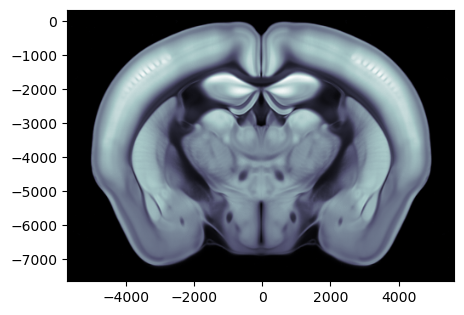

In [11]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)
image_volume = atlas.image
label_volume = atlas.label

ap_coordinate = -1000 / 1e6  
fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_cslice(ap_coordinate, volume='image', ax=ax)
plt.show()

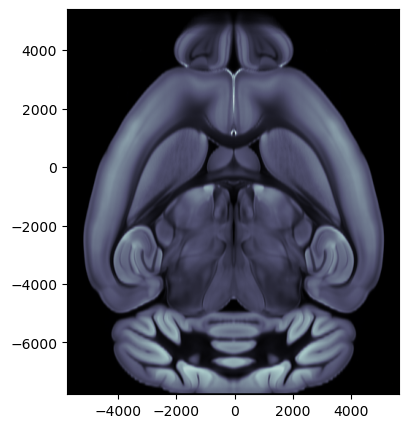

In [12]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)

dv_coordinate = -3000 / 1e6  
fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_hslice(dv_coordinate, volume='image', ax=ax)
plt.show()

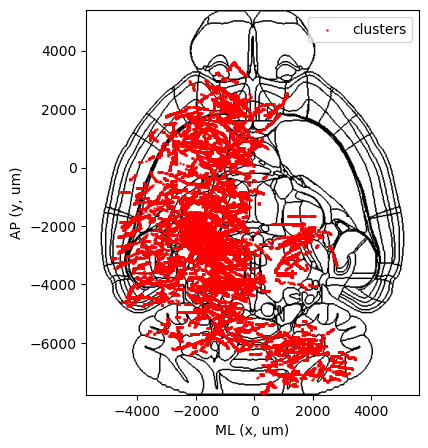

In [14]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)

x_vals = [unit['x'] * 1e6 for unit in filtered_units]
y_vals = [unit['y'] * 1e6 for unit in filtered_units]
z_vals = [unit['z'] * 1e6 for unit in filtered_units]

dv_coordinate = -3500 / 1e6 

fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_hslice(dv_coordinate, volume='boundary', ax=ax)

ax.scatter(x_vals, y_vals, c='red', s=1, alpha=0.7, label="clusters")

ax.set_xlabel("ML (x, um)")
ax.set_ylabel("AP (y, um)")
ax.legend()
plt.savefig("./result/slice_plot.tiff", format="tif", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_1617957/3372309364.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


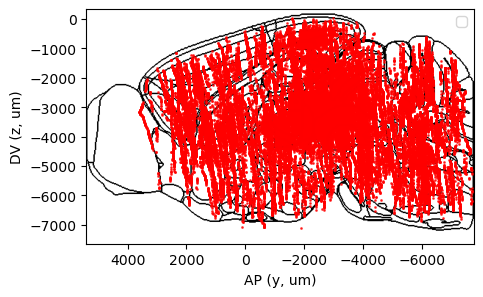

In [16]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)

x_vals = [unit['x'] * 1e6 for unit in filtered_units]
y_vals = [unit['y'] * 1e6 for unit in filtered_units]
z_vals = [unit['z'] * 1e6 for unit in filtered_units]

ml_coordinate = -800 / 1e6  
fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_sslice(ml_coordinate, volume='boundary', ax=ax)

ax.scatter(y_vals, z_vals, c='red', s=1, alpha=0.7, label="")

ax.set_xlabel("AP (y, um)")
ax.set_ylabel("DV (z, um)")
ax.legend()
plt.savefig("./result/slice_plot2.tiff", format="tif", dpi=300, bbox_inches="tight")
plt.show()

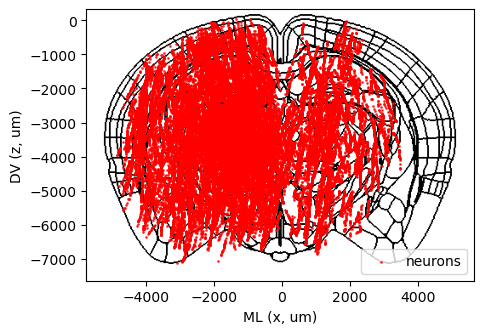

In [12]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)

x_vals = [unit['x'] * 1e6 for unit in filtered_units]
y_vals = [unit['y'] * 1e6 for unit in filtered_units]
z_vals = [unit['z'] * 1e6 for unit in filtered_units]

ap_coordinate = -2000 / 1e6 

fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_cslice(ap_coordinate, volume='boundary', ax=ax)

ax.scatter(x_vals, z_vals, c='red', s=1, alpha=0.7, label="neurons")

ax.set_xlabel("ML (x, um)")
ax.set_ylabel("DV (z, um)")
ax.legend()
plt.show()

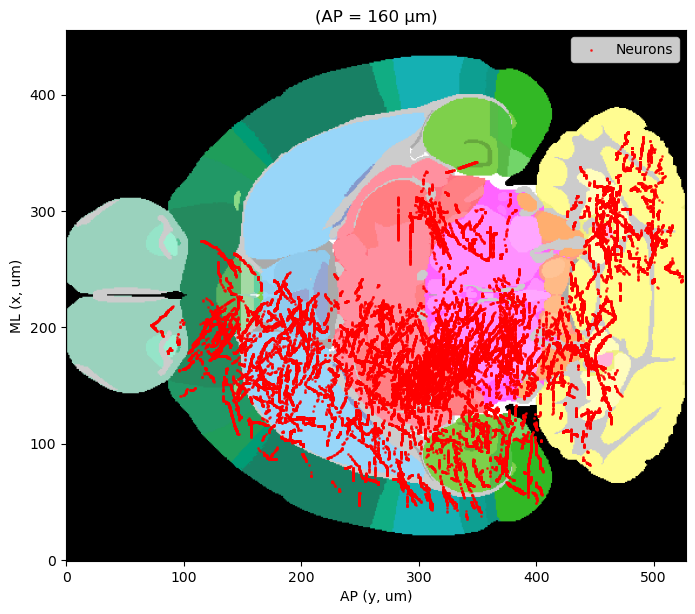

In [81]:
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25) #y,x,z (528,456,320)

ccf_coords = []
for unit in filtered_units:
    x, y, z = unit['x'], unit['y'], unit['z']
    ccf = atlas.xyz2ccf(np.array([[x, y, z]])) 
    ccf_coords.append(ccf[0])  

dv_coordinate = 160  

img1 = sitk.ReadImage("../ccf-v3/annotation_25_recolor.nrrd")   #x,z,y (456, 320, 528)
array1 = sitk.GetArrayFromImage(img1)

fig, ax = plt.subplots(figsize=(8, 6.89))

rotated_image = np.rot90(array1[:, dv_coordinate, :], k=0)  # k=3 for 90 degrees clockwise rotation
plt.imshow(rotated_image, cmap='gray', aspect='auto')

x_vals = [coord[1] / 25 for coord in ccf_coords]  
y_vals = [coord[0] / 25 for coord in ccf_coords]  # CCF y 坐标
ax.scatter(x_vals, y_vals, c='red', s=1, alpha=0.7, label="Neurons")
ax.invert_yaxis()

ax.set_xlabel("AP (y, um)")
ax.set_ylabel("ML (x, um)")
ax.set_title(f"(AP = {ap_coordinate} μm)")
ax.legend()

plt.show()

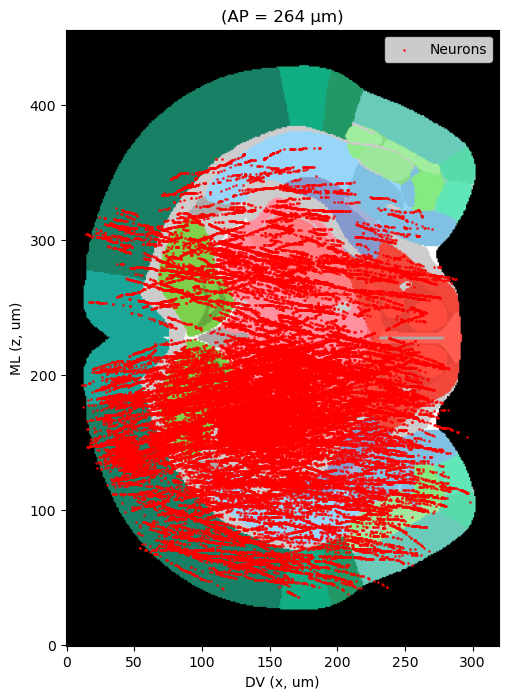

In [107]:
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25) #y,x,z (528,456,320)

ccf_coords = []
for unit in filtered_units:
    x, y, z = unit['x'], unit['y'], unit['z']
    ccf = atlas.xyz2ccf(np.array([[x, y, z]])) 
    ccf_coords.append(ccf[0])  

ap_coordinate = 264 

img1 = sitk.ReadImage("../ccf-v3/annotation_25_recolor.nrrd")   #x,z,y (456, 320, 528)
array1 = sitk.GetArrayFromImage(img1)

fig, ax = plt.subplots(figsize=(5.59, 8))

rotated_image = np.rot90(array1[:, :, ap_coordinate], k=0)  
plt.imshow(rotated_image, cmap='gray', aspect='auto')

x_vals = [coord[2] / 25 for coord in ccf_coords]  
z_vals = [coord[0] / 25 for coord in ccf_coords] 
ax.scatter(x_vals, z_vals, c='red', s=1, alpha=0.7, label="Neurons")
ax.invert_yaxis()

ax.set_xlabel("DV (x, um)")
ax.set_ylabel("ML (z, um)")
ax.set_title(f"(AP = {ap_coordinate} μm)")
ax.legend()


plt.show()

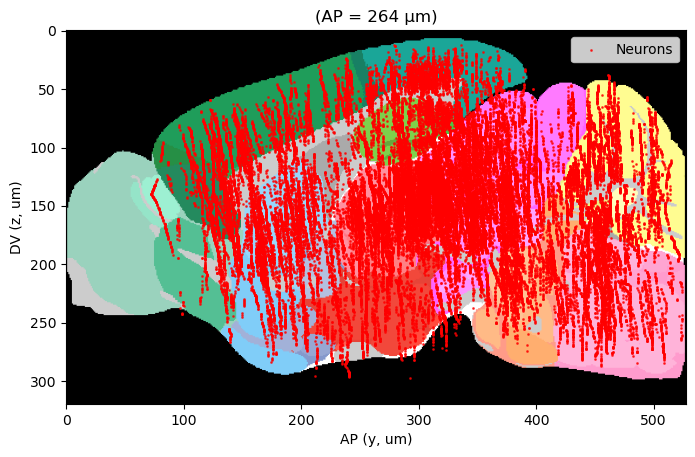

In [104]:
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25) 

ccf_coords = []
for unit in filtered_units:
    x, y, z = unit['x'], unit['y'], unit['z']
    ccf = atlas.xyz2ccf(np.array([[x, y, z]])) 
    ccf_coords.append(ccf[0])  

ml_coordinate = 273

img1 = sitk.ReadImage("../ccf-v3/annotation_25_recolor.nrrd")  
array1 = sitk.GetArrayFromImage(img1)

fig, ax = plt.subplots(figsize=(8, 4.85))

rotated_image = np.rot90(array1[ml_coordinate, :, :], k=0)  
plt.imshow(rotated_image, cmap='gray', aspect='auto')

y_vals = [coord[1] / 25 for coord in ccf_coords]  
z_vals = [coord[2] / 25 for coord in ccf_coords]  
ax.scatter(y_vals, z_vals, c='red', s=1, alpha=0.7, label="Neurons")
#ax.invert_yaxis()

ax.set_xlabel("AP (y, um)")
ax.set_ylabel("DV (z, um)")
ax.set_title(f"(AP = {ap_coordinate} μm)")
ax.legend()

plt.show()

## 2. aggregate in region(10)

### 2.1 StimOn -> firstMovement

In [7]:
import numpy as np
import pandas as pd
from collections import defaultdict
from brainbox.io.one import SessionLoader
from one.api import ONE
from tqdm import tqdm
import pandas as pd

one = ONE()

eid_to_trials = {}

for eid in unit_df['eid'].unique():
    sl = SessionLoader(eid=eid, one=one)
    sl.load_trials()
    
    stimOn_times = sl.trials['stimOn_times']
    firstMove_times = sl.trials['firstMovement_times']
    
    trial_df = pd.DataFrame({
        'trial_id': range(len(stimOn_times)),
        'start_time': stimOn_times,
        'end_time': firstMove_times,
        'duration': firstMove_times - stimOn_times
    })
    
    eid_to_trials[eid] = trial_df[['start_time', 'end_time']].values

import pickle

# 保存
with open('eid_to_trials.pkl', 'wb') as f:
    pickle.dump(eid_to_trials, f)

local md5 mismatch on dataset: cortexlab/Subjects/KS023/2019-12-06/001/alf/_ibl_trials.goCueTrigger_times.npy
(S3) /home/ylx/project/SC_FC/BWM/cortexlab/Subjects/KS023/2019-12-06/001/alf/_ib
/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/one/util.py:406: ALFWarning: No default revision for dataset alf/_ibl_trials.table.pqt; using most recent
  warnings.warn(
/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/one/util.py:428: ALFWarning: Multiple revisions: "", "2024-02-22"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)
local md5 mismatch on dataset: cortexlab/Subjects/KS023/2019-12-08/001/alf/_ibl_trials.goCueTrigger_times.npy
(S3) /home/ylx/project/SC_FC/BWM/cortexlab/Subjects/KS023/2019-12-08/001/alf/_ib
local md5 mismatch on dataset: cortexlab/Subjects/KS023/2019-12-10/001/alf/_ibl_trials.goCueTrigger_times.npy
(S3) /home/ylx/project/SC_FC/BWM/cortexlab/Subjects/KS023/2019-12-10/001/alf/_ib
local md5 mismatch on dataset: zadorlab/Subj

In [8]:
import pickle

with open('eid_to_trials.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)

eid_to_trials

{'37e96d0b-5b4b-4c6e-9b29-7edbdc94bbd0': array([[  43.81173333,   43.9939    ],
        [  47.2617    ,   47.4269    ],
        [  50.5122    ,   50.4069    ],
        ...,
        [2772.2432    , 2779.8799    ],
        [2819.20946667, 2820.3499    ],
        [2823.89273333, 2826.9069    ]]),
 '57b5ae8f-d446-4161-b439-b191c5e3e77b': array([[  50.45603333,   50.59723333],
        [  60.22266667,   60.14923333],
        [  70.3343    ,   70.48123333],
        ...,
        [4652.76083333, 4693.63923333],
        [4697.9391    , 4748.65223333],
        [4753.02646667, 4765.69623333]]),
 '0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde': array([[  38.64410187,   38.69039986],
        [  41.56071018,   41.68239986],
        [  46.69073046,   46.81639986],
        ...,
        [5413.69614292, 5413.81639986],
        [5418.96274954, 5418.75439986],
        [5423.22945616, 5423.21539986]]),
 '113c5b6c-940e-4b21-b462-789b4c2be0e5': array([[  80.81208465,   85.04245141],
        [  90.26300613,   90.482451

In [16]:
one = ONE()

import pickle
from collections import defaultdict
import numpy as np

def get_level1_region_id(region_id, region_table):
    terminate_ids = {549, 698, 703, 623, 1089, 1097, 1065, 313, 315, 512}
    table = region_table.set_index('atlas_id')

    if region_id not in table.index:
        return None

    current_id = region_id
    while True:
        if current_id in terminate_ids:
            return current_id

        row = table.loc[current_id]

        parent = row['parent']
        if pd.isna(parent):
            return current_id

        try:
            parent = int(parent)
        except (ValueError, TypeError):
            return current_id

        if parent not in table.index:
            return current_id

        current_id = parent

###########################################################

with open('eid_to_trials.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)


brain_region_data = defaultdict(list)

for unit in all_units[:]:
    pid = unit['pid']
    cluster_id = unit['cluster_id']
    region_id = unit['atlas_id']
    level1_id = get_level1_region_id(region_id, region_table)
    #acronym = region_table.loc[region_table['atlas_id'] == level1_id, 'acronym'].values[0]

    matched = unit_df[(unit_df['pid'] == pid) & (unit_df['cluster_id'] == cluster_id)]
    if matched.empty:
        continue
    eid = matched['eid'].values[0]

    trials = eid_to_trials.get(eid, [])
    if len(trials) == 0:
        continue

    for trial_start, trial_end in trials:  
        spike_mask = (unit['spike_times'] >= trial_start) & (unit['spike_times'] <= trial_end)
        if np.sum(spike_mask) == 0:
            continue

        spike_times_rel = unit['spike_times'][spike_mask] - trial_start 
        spike_times_std = spike_times_rel / (trial_end - trial_start)    
        spike_voltages = unit['spike_voltage'][spike_mask]

        brain_region_data[level1_id].append({
            'spike_times': spike_times_std,
            'spike_voltages': spike_voltages
        })

brain_region_avg_voltage = {}
for region_id, units in brain_region_data.items():
    all_times = np.concatenate([u['spike_times'] for u in units])
    all_voltages = np.concatenate([u['spike_voltages'] for u in units])

    sort_idx = np.argsort(all_times)
    all_times_sorted = all_times[sort_idx]
    all_voltages_sorted = all_voltages[sort_idx]

    brain_region_avg_voltage[region_id] = {
        'spike_times': all_times_sorted,
        'spike_voltages': all_voltages_sorted
    }

print(f"共整合了 {len(brain_region_avg_voltage)} 个脑区的 spike 数据")

共整合了 10 个脑区的 spike 数据


In [19]:
import pickle

with open('brain_region_10_avg_voltage_StimOn-firstMovement.pkl', 'wb') as f:
    pickle.dump(brain_region_avg_voltage, f)

In [17]:
import pickle

with open('brain_region_10_avg_voltage_StimOn-firstMovement.pkl', 'rb') as f:
    brain_region_avg_voltage = pickle.load(f)

In [3]:
import numpy as np

def build_region_binned_traces_nan(aligned_region_data,
                                   dt=0.01,
                                   duration_mode='percentile',
                                   duration_percentile=100):

    end_times = []
    for rid, d in aligned_region_data.items():
        t = d.get('spike_times', None)
        if t is None or len(t) == 0:
            end_times.append(0.0)
        else:
            end_times.append(float(np.max(t)))
    end_times = np.array(end_times)

    if duration_mode == 'min':
        used_duration = float(np.min(end_times))
    elif duration_mode == 'median':
        used_duration = float(np.median(end_times))
    elif duration_mode == 'percentile':
        used_duration = float(np.percentile(end_times, duration_percentile))
    elif duration_mode == 'max':
        used_duration = float(np.max(end_times))
    else:
        raise ValueError("duration_mode must be 'min'|'median'|'percentile'|'max'")

    if used_duration <= 0:
        raise ValueError("used_duration <= 0, check your data")

    edges = np.arange(0.0, used_duration + dt, dt)
    centers = edges[:-1] + dt / 2.0
    n_bins = len(centers)

    binned = {}
    for rid, d in aligned_region_data.items():
        times = np.asarray(d.get('spike_times', []))
        volts = d.get('spike_voltages', None)

        region_bin = np.full(n_bins, np.nan, dtype=float)

        if times.size == 0:
            binned[rid] = region_bin
            continue

        mask = (times >= 0) & (times < used_duration)
        times_cut = times[mask]
        if volts is not None:
            volts_cut = np.asarray(volts)[mask]
        else:
            volts_cut = None

        bin_indices = np.digitize(times_cut, edges) - 1
        valid = (bin_indices >= 0) & (bin_indices < n_bins)
        bin_indices = bin_indices[valid]
        if volts_cut is not None:
            volts_cut = volts_cut[valid]
            sums = np.zeros(n_bins)
            counts = np.zeros(n_bins)
            np.add.at(sums, bin_indices, volts_cut)
            np.add.at(counts, bin_indices, 1)
            avg = np.divide(sums, counts, out=np.full_like(sums, np.nan), where=counts > 0)
            region_bin = avg
        else:
            counts = np.zeros(n_bins)
            np.add.at(counts, bin_indices, 1)
            region_bin[counts > 0] = counts[counts > 0]  

        binned[rid] = region_bin

    return centers, binned, used_duration

自动设置的行间距: 2.20


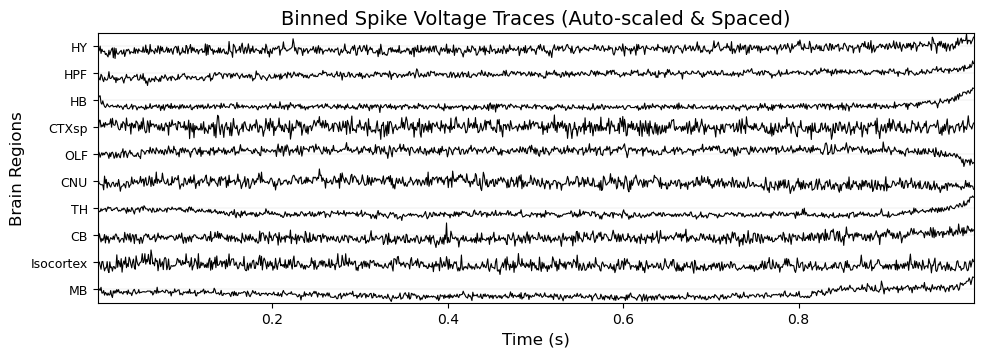

✅ 图像已保存到: result/fig/brain_region_binned_traces_StimOn-firstMovement.png


In [20]:
import matplotlib.pyplot as plt
import os
import numpy as np
from iblatlas.regions import BrainRegions


def plot_brain_region_traces(binned_traces, time_axis, output_dir="result/fig",
                             auto_spacing=True, compact=True, dpi=600):

    br = BrainRegions()
    atlas_id_to_acronym = dict(zip(br.id, br.acronym))

    region_ids = sorted(list(binned_traces.keys()))
    region_names = [atlas_id_to_acronym.get(abs(rid), str(rid)) for rid in region_ids]

    scaled_traces = []
    max_amplitudes = []

    for rid in region_ids:
        trace = np.nan_to_num(binned_traces[rid])
        if np.max(trace) - np.min(trace) > 0:
            trace_scaled = (trace - np.min(trace)) / (np.max(trace) - np.min(trace)) * 2 - 1
        else:
            trace_scaled = trace
        scaled_traces.append(trace_scaled)
        max_amplitudes.append(np.max(np.abs(trace_scaled)))


    if auto_spacing:
        mean_amp = np.median(max_amplitudes)
        offset_step = 2.2 * mean_amp  
    else:
        offset_step = 2.0
    print(f"自动设置的行间距: {offset_step:.2f}")

    fig_height = max(3, len(region_ids) * 0.18)
    fig, ax = plt.subplots(figsize=(12, fig_height))

    for i, trace_scaled in enumerate(scaled_traces):
        base = i * offset_step
        ax.axhline(base, color='gray', lw=0.3, alpha=0.3)
        ax.plot(time_axis, trace_scaled + base, lw=0.8, color="black")

    ytick_positions = np.arange(0, len(region_ids) * offset_step, offset_step)
    ax.set_yticks(ytick_positions)
    ax.set_yticklabels(region_names, fontsize=9)

    ax.set_xlabel("Time (s)", fontsize=12)
    ax.set_ylabel("Brain Regions", fontsize=12)
    ax.set_title("Binned Spike Voltage Traces (Auto-scaled & Spaced)", fontsize=14)

    if compact:
        ax.set_ylim(-offset_step * 0.5, len(region_ids) * offset_step - offset_step * 0.5)
        plt.margins(x=0, y=0.01)
        plt.subplots_adjust(left=0.25, right=0.98, top=0.95, bottom=0.05)
    else:
        plt.tight_layout(pad=0.3)

    os.makedirs(output_dir, exist_ok=True)
    output_path = os.path.join(output_dir, "brain_region_binned_traces_StimOn-firstMovement.png")
    plt.savefig(output_path, dpi=dpi, bbox_inches="tight")
    plt.show()

    print(f"✅ 图像已保存到: {output_path}")

############################################################################################

with open('brain_region_10_avg_voltage_StimOn-firstMovement.pkl', 'rb') as f:
    brain_region_avg_voltage = pickle.load(f)

time_axis, binned_traces, duration = build_region_binned_traces_nan(brain_region_avg_voltage, dt=0.001)
plot_brain_region_traces(binned_traces, time_axis)

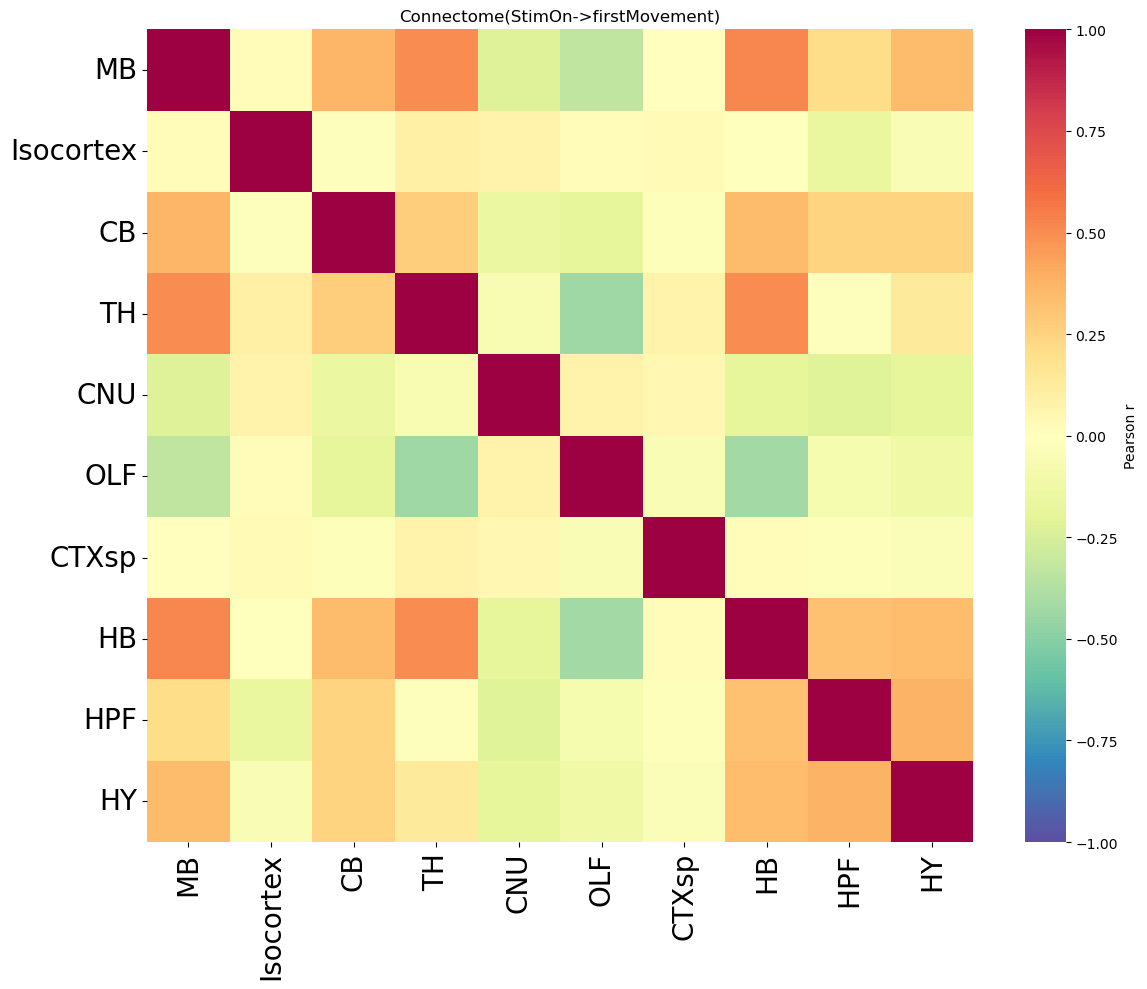

✅ Connectome 已保存到: result/fig/region_connectome_10_StimOn-firstMovement.png


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from iblatlas.regions import BrainRegions

os.makedirs("result/fig", exist_ok=True)

region_ids = sorted(binned_traces.keys())

region_matrix = np.array([binned_traces[rid] for rid in region_ids])

region_matrix = (region_matrix - region_matrix.mean(axis=1, keepdims=True)) / \
                 (region_matrix.std(axis=1, keepdims=True) + 1e-9)

corr_matrix = np.corrcoef(region_matrix)
corr_matrix_1 = corr_matrix

br = BrainRegions()
region_labels = [
    br.acronym[np.where(br.id == rid)[0][0]] if rid in br.id else str(rid)
    for rid in region_ids
]

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, 
            xticklabels=region_labels, 
            yticklabels=region_labels,
            cmap='Spectral_r', vmin=-1, vmax=1, cbar_kws={'label': 'Pearson r'})

plt.title(f"Connectome(StimOn->firstMovement)")
plt.xticks(rotation=90, fontsize=20)
plt.yticks(rotation=0, fontsize=20)
plt.tight_layout()

out_path = "result/fig/region_connectome_10_StimOn-firstMovement.png"
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Connectome 已保存到: {out_path}")

### 2.2 firstMovement -> responds

In [9]:
import numpy as np
import pandas as pd
from collections import defaultdict
from brainbox.io.one import SessionLoader
from one.api import ONE
from tqdm import tqdm
import pandas as pd

one = ONE()

eid_to_trials = {}

for eid in unit_df['eid'].unique():
    sl = SessionLoader(eid=eid, one=one)
    sl.load_trials()
    
    Time_start = sl.trials['firstMovement_times']
    Time_end = sl.trials['response_times']
    
    trial_df = pd.DataFrame({
        'trial_id': range(len(Time_start)),
        'start_time': Time_start,
        'end_time': Time_end,
        'duration': Time_start - Time_end
    })
    
    eid_to_trials[eid] = trial_df[['start_time', 'end_time']].values

import pickle

with open('eid_to_trials_firstMovement2response.pkl', 'wb') as f:
    pickle.dump(eid_to_trials, f)

local md5 mismatch on dataset: cortexlab/Subjects/KS023/2019-12-06/001/alf/_ibl_trials.goCueTrigger_times.npy
(S3) /home/ylx/project/SC_FC/BWM/cortexlab/Subjects/KS023/2019-12-06/001/alf/_ib
/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/one/util.py:406: ALFWarning: No default revision for dataset alf/_ibl_trials.table.pqt; using most recent
  warnings.warn(
/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/one/util.py:428: ALFWarning: Multiple revisions: "", "2024-02-22"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)
local md5 mismatch on dataset: cortexlab/Subjects/KS023/2019-12-08/001/alf/_ibl_trials.goCueTrigger_times.npy
(S3) /home/ylx/project/SC_FC/BWM/cortexlab/Subjects/KS023/2019-12-08/001/alf/_ib
local md5 mismatch on dataset: cortexlab/Subjects/KS023/2019-12-10/001/alf/_ibl_trials.goCueTrigger_times.npy
(S3) /home/ylx/project/SC_FC/BWM/cortexlab/Subjects/KS023/2019-12-10/001/alf/_ib
local md5 mismatch on dataset: zadorlab/Subj

In [ ]:
one = ONE()

import pickle
from collections import defaultdict
import numpy as np

def get_level1_region_id(region_id, region_table):
    terminate_ids = {549, 698, 703, 623, 1089, 1097, 1065, 313, 315, 512}
    table = region_table.set_index('atlas_id')

    if region_id not in table.index:
        return None

    current_id = region_id
    while True:
        if current_id in terminate_ids:
            return current_id

        row = table.loc[current_id]

        parent = row['parent']
        if pd.isna(parent):
            return current_id

        try:
            parent = int(parent)
        except (ValueError, TypeError):
            return current_id

        if parent not in table.index:
            return current_id

        current_id = parent

###########################################################

with open('eid_to_trials_firstMovement2response.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)


brain_region_data = defaultdict(list)

for unit in all_units[:]:
    pid = unit['pid']
    cluster_id = unit['cluster_id']
    region_id = unit['atlas_id']
    level1_id = get_level1_region_id(region_id, region_table)

    matched = unit_df[(unit_df['pid'] == pid) & (unit_df['cluster_id'] == cluster_id)]
    if matched.empty:
        continue
    eid = matched['eid'].values[0]

    trials = eid_to_trials.get(eid, [])
    if len(trials) == 0:
        continue

    for trial_start, trial_end in trials:  
        spike_mask = (unit['spike_times'] >= trial_start) & (unit['spike_times'] <= trial_end)
        if np.sum(spike_mask) == 0:
            continue

        spike_times_rel = unit['spike_times'][spike_mask] - trial_start  
        spike_times_std = spike_times_rel / (trial_end - trial_start)    
        spike_voltages = unit['spike_voltage'][spike_mask]

        brain_region_data[level1_id].append({
            'spike_times': spike_times_std,
            'spike_voltages': spike_voltages
        })

brain_region_avg_voltage = {}
for region_id, units in brain_region_data.items():
    all_times = np.concatenate([u['spike_times'] for u in units])
    all_voltages = np.concatenate([u['spike_voltages'] for u in units])

    sort_idx = np.argsort(all_times)
    all_times_sorted = all_times[sort_idx]
    all_voltages_sorted = all_voltages[sort_idx]

    brain_region_avg_voltage[region_id] = {
        'spike_times': all_times_sorted,
        'spike_voltages': all_voltages_sorted
    }

########################################################
import pickle

with open('brain_region_avg_voltage_firstMovement2response.pkl', 'wb') as f:
    pickle.dump(brain_region_avg_voltage, f)

自动设置的行间距: 2.20


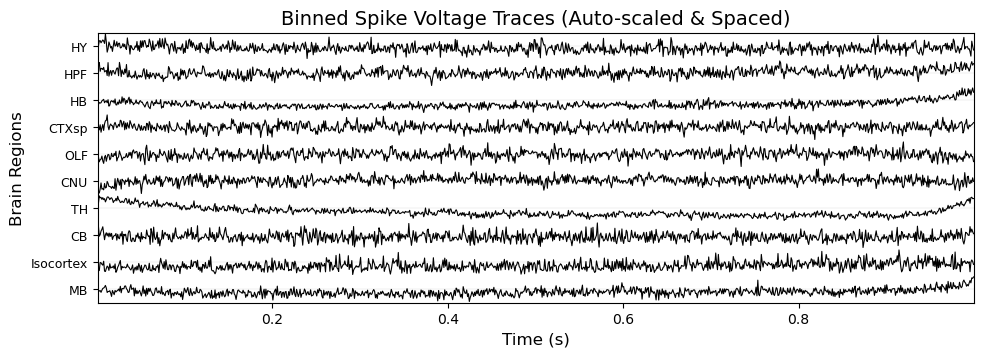

✅ 图像已保存到: result/fig/brain_region_binned_traces_firstMovement-response.png


In [4]:
import matplotlib.pyplot as plt
import os
import numpy as np
import pickle
from iblatlas.regions import BrainRegions


def plot_brain_region_traces(binned_traces, time_axis, output_dir="result/fig",
                             auto_spacing=True, compact=True, dpi=600):

    br = BrainRegions()
    atlas_id_to_acronym = dict(zip(br.id, br.acronym))

    region_ids = sorted(list(binned_traces.keys()))
    region_names = [atlas_id_to_acronym.get(abs(rid), str(rid)) for rid in region_ids]

    scaled_traces = []
    max_amplitudes = []

    for rid in region_ids:
        trace = np.nan_to_num(binned_traces[rid])
        if np.max(trace) - np.min(trace) > 0:
            trace_scaled = (trace - np.min(trace)) / (np.max(trace) - np.min(trace)) * 2 - 1
        else:
            trace_scaled = trace
        scaled_traces.append(trace_scaled)
        max_amplitudes.append(np.max(np.abs(trace_scaled)))

    if auto_spacing:
        mean_amp = np.median(max_amplitudes)
        offset_step = 2.2 * mean_amp  
    else:
        offset_step = 2.0
    print(f"自动设置的行间距: {offset_step:.2f}")

    fig_height = max(3, len(region_ids) * 0.18)
    fig, ax = plt.subplots(figsize=(12, fig_height))

    for i, trace_scaled in enumerate(scaled_traces):
        base = i * offset_step
        ax.axhline(base, color='gray', lw=0.3, alpha=0.3)
        ax.plot(time_axis, trace_scaled + base, lw=0.8, color="black")

    ytick_positions = np.arange(0, len(region_ids) * offset_step, offset_step)
    ax.set_yticks(ytick_positions)
    ax.set_yticklabels(region_names, fontsize=9)

    ax.set_xlabel("Time (s)", fontsize=12)
    ax.set_ylabel("Brain Regions", fontsize=12)
    ax.set_title("Binned Spike Voltage Traces (Auto-scaled & Spaced)", fontsize=14)

    if compact:
        ax.set_ylim(-offset_step * 0.5, len(region_ids) * offset_step - offset_step * 0.5)
        plt.margins(x=0, y=0.01)
        plt.subplots_adjust(left=0.25, right=0.98, top=0.95, bottom=0.05)
    else:
        plt.tight_layout(pad=0.3)

    os.makedirs(output_dir, exist_ok=True)
    output_path = os.path.join(output_dir, "brain_region_binned_traces_firstMovement-response.png")
    plt.savefig(output_path, dpi=dpi, bbox_inches="tight")
    plt.show()

    print(f"✅ 图像已保存到: {output_path}")

#######################################################################################################
with open('brain_region_10_avg_voltage_firstMovement2response.pkl', 'rb') as f:
    brain_region_avg_voltage = pickle.load(f)

time_axis, binned_traces, duration = build_region_binned_traces_nan(brain_region_avg_voltage, dt=0.001)
plot_brain_region_traces(binned_traces, time_axis)

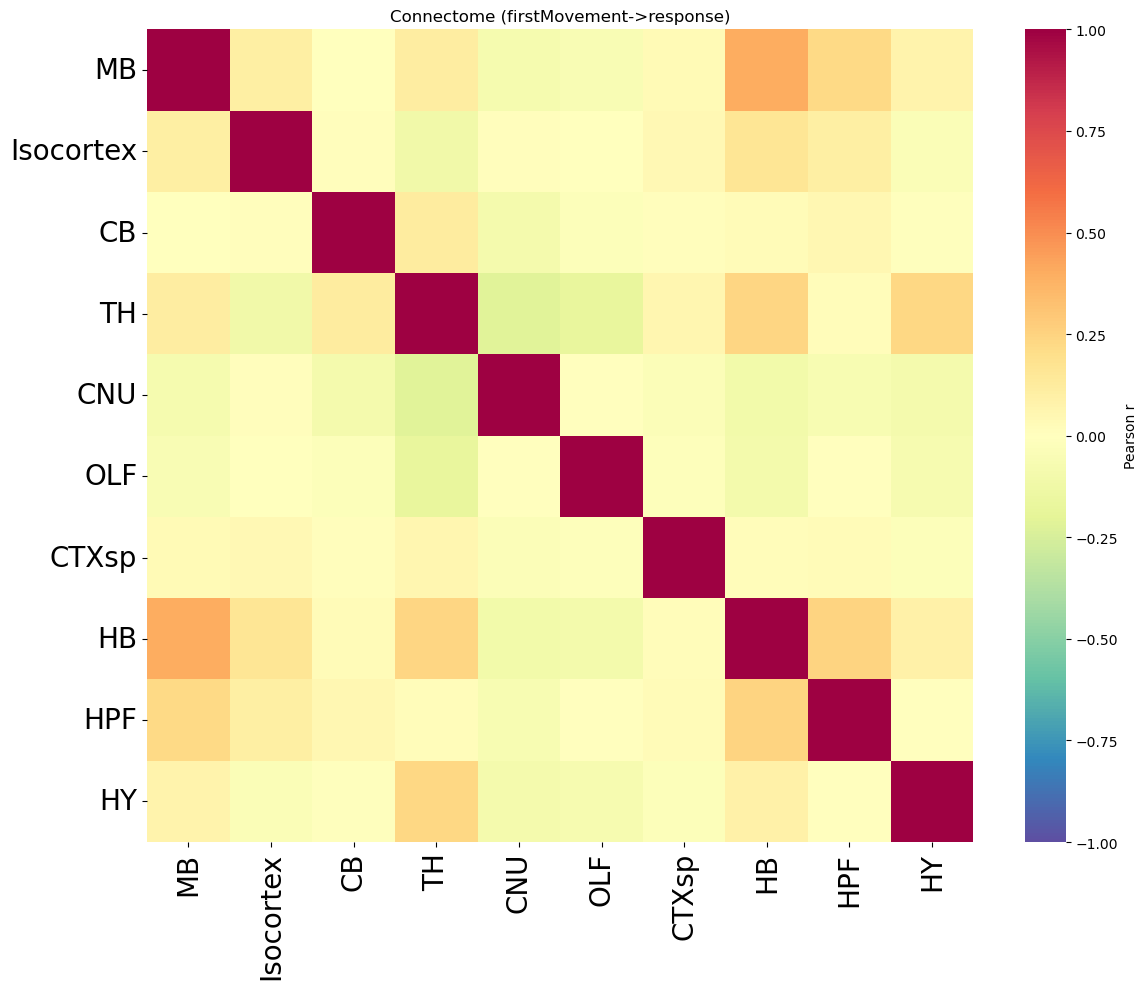

✅ Connectome 已保存到: result/fig/region_connectome_10_firstMovement-response.png


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from iblatlas.regions import BrainRegions

os.makedirs("result/fig", exist_ok=True)

region_ids = sorted(binned_traces.keys())

region_matrix = np.array([binned_traces[rid] for rid in region_ids])

region_matrix = (region_matrix - region_matrix.mean(axis=1, keepdims=True)) / \
                 (region_matrix.std(axis=1, keepdims=True) + 1e-9)

corr_matrix = np.corrcoef(region_matrix)
corr_matrix_2 = corr_matrix
br = BrainRegions()
region_labels = [
    br.acronym[np.where(br.id == rid)[0][0]] if rid in br.id else str(rid)
    for rid in region_ids
]

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, 
            xticklabels=region_labels, 
            yticklabels=region_labels,
            cmap='Spectral_r', vmin=-1, vmax=1, cbar_kws={'label': 'Pearson r'})

plt.title(f"Connectome (firstMovement->response)")
plt.xticks(rotation=90, fontsize=20)
plt.yticks(rotation=0, fontsize=20)
plt.tight_layout()

out_path = "result/fig/region_connectome_10_firstMovement-response.png"
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Connectome 已保存到: {out_path}")

### 2.3 feedback -> intervals_1

In [16]:
import numpy as np
import pandas as pd
from collections import defaultdict
from brainbox.io.one import SessionLoader
from one.api import ONE
from tqdm import tqdm
import pandas as pd

one = ONE()

eid_to_trials = {}

for eid in unit_df['eid'].unique():
    sl = SessionLoader(eid=eid, one=one)
    sl.load_trials()
    
    Time_start = sl.trials['feedback_times']
    Time_end = sl.trials['intervals_1']
    
    trial_df = pd.DataFrame({
        'trial_id': range(len(Time_start)),
        'start_time': Time_start,
        'end_time': Time_end,
        'duration': Time_start - Time_end
    })
    
    eid_to_trials[eid] = trial_df[['start_time', 'end_time']].values

import pickle

with open('eid_to_trials_feedback2intervals1.pkl', 'wb') as f:
    pickle.dump(eid_to_trials, f)

local md5 mismatch on dataset: cortexlab/Subjects/KS023/2019-12-06/001/alf/_ibl_trials.goCueTrigger_times.npy
(S3) /home/ylx/project/SC_FC/BWM/cortexlab/Subjects/KS023/2019-12-06/001/alf/_ib
/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/one/util.py:406: ALFWarning: No default revision for dataset alf/_ibl_trials.table.pqt; using most recent
  warnings.warn(
/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/one/util.py:428: ALFWarning: Multiple revisions: "", "2024-02-22"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)
local md5 mismatch on dataset: cortexlab/Subjects/KS023/2019-12-08/001/alf/_ibl_trials.goCueTrigger_times.npy
(S3) /home/ylx/project/SC_FC/BWM/cortexlab/Subjects/KS023/2019-12-08/001/alf/_ib
local md5 mismatch on dataset: cortexlab/Subjects/KS023/2019-12-10/001/alf/_ibl_trials.goCueTrigger_times.npy
(S3) /home/ylx/project/SC_FC/BWM/cortexlab/Subjects/KS023/2019-12-10/001/alf/_ib
local md5 mismatch on dataset: zadorlab/Subj

In [ ]:
import pickle
from collections import defaultdict
import numpy as np

def get_level1_region_id(region_id, region_table):
    terminate_ids = {549, 698, 703, 623, 1089, 1097, 1065, 313, 315, 512}
    table = region_table.set_index('atlas_id')

    if region_id not in table.index:
        return None

    current_id = region_id
    while True:
        if current_id in terminate_ids:
            return current_id

        row = table.loc[current_id]

        parent = row['parent']
        if pd.isna(parent):
            return current_id

        try:
            parent = int(parent)
        except (ValueError, TypeError):
            return current_id

        if parent not in table.index:
            return current_id

        # 向上移动一层
        current_id = parent

###########################################################

with open('eid_to_trials_feedback2intervals1.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)


brain_region_data = defaultdict(list)

for unit in all_units[:]:
    pid = unit['pid']
    cluster_id = unit['cluster_id']
    region_id = unit['atlas_id']
    level1_id = get_level1_region_id(region_id, region_table)

    matched = unit_df[(unit_df['pid'] == pid) & (unit_df['cluster_id'] == cluster_id)]
    if matched.empty:
        continue
    eid = matched['eid'].values[0]

    trials = eid_to_trials.get(eid, [])
    if len(trials) == 0:
        continue

    for trial_start, trial_end in trials:  
        spike_mask = (unit['spike_times'] >= trial_start) & (unit['spike_times'] <= trial_end)
        if np.sum(spike_mask) == 0:
            continue

        spike_times_rel = unit['spike_times'][spike_mask] - trial_start  
        spike_times_std = spike_times_rel / (trial_end - trial_start)    
        spike_voltages = unit['spike_voltage'][spike_mask]

        brain_region_data[level1_id].append({
            'spike_times': spike_times_std,
            'spike_voltages': spike_voltages
        })

brain_region_avg_voltage = {}
for region_id, units in brain_region_data.items():
    all_times = np.concatenate([u['spike_times'] for u in units])
    all_voltages = np.concatenate([u['spike_voltages'] for u in units])

    sort_idx = np.argsort(all_times)
    all_times_sorted = all_times[sort_idx]
    all_voltages_sorted = all_voltages[sort_idx]

    brain_region_avg_voltage[region_id] = {
        'spike_times': all_times_sorted,
        'spike_voltages': all_voltages_sorted
    }

########################################################
import pickle

with open('brain_region_avg_voltage_feedback2intervals1.pkl', 'wb') as f:
    pickle.dump(brain_region_avg_voltage, f)

自动设置的行间距: 2.20


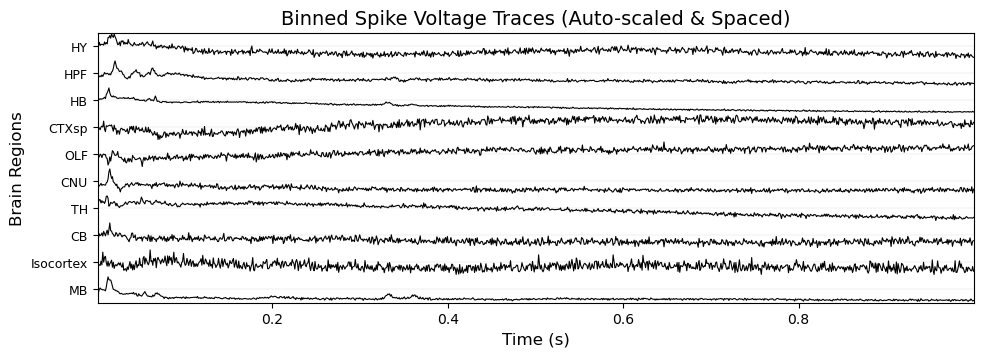

✅ 图像已保存到: result/fig/brain_region_binned_traces_feedback-intervals1.png


In [6]:
import matplotlib.pyplot as plt
import os
import numpy as np
from iblatlas.regions import BrainRegions


def plot_brain_region_traces(binned_traces, time_axis, output_dir="result/fig",
                             auto_spacing=True, compact=True, dpi=600):

    br = BrainRegions()
    atlas_id_to_acronym = dict(zip(br.id, br.acronym))

    region_ids = sorted(list(binned_traces.keys()))
    region_names = [atlas_id_to_acronym.get(abs(rid), str(rid)) for rid in region_ids]

    scaled_traces = []
    max_amplitudes = []

    for rid in region_ids:
        trace = np.nan_to_num(binned_traces[rid])
        if np.max(trace) - np.min(trace) > 0:
            trace_scaled = (trace - np.min(trace)) / (np.max(trace) - np.min(trace)) * 2 - 1
        else:
            trace_scaled = trace
        scaled_traces.append(trace_scaled)
        max_amplitudes.append(np.max(np.abs(trace_scaled)))

    if auto_spacing:
        mean_amp = np.median(max_amplitudes)
        offset_step = 2.2 * mean_amp  
    else:
        offset_step = 2.0
    print(f"自动设置的行间距: {offset_step:.2f}")

    fig_height = max(3, len(region_ids) * 0.18)
    fig, ax = plt.subplots(figsize=(12, fig_height))

    for i, trace_scaled in enumerate(scaled_traces):
        base = i * offset_step
        ax.axhline(base, color='gray', lw=0.3, alpha=0.3)
        ax.plot(time_axis, trace_scaled + base, lw=0.8, color="black")

    ytick_positions = np.arange(0, len(region_ids) * offset_step, offset_step)
    ax.set_yticks(ytick_positions)
    ax.set_yticklabels(region_names, fontsize=9)

    ax.set_xlabel("Time (s)", fontsize=12)
    ax.set_ylabel("Brain Regions", fontsize=12)
    ax.set_title("Binned Spike Voltage Traces (Auto-scaled & Spaced)", fontsize=14)

    if compact:
        ax.set_ylim(-offset_step * 0.5, len(region_ids) * offset_step - offset_step * 0.5)
        plt.margins(x=0, y=0.01)
        plt.subplots_adjust(left=0.25, right=0.98, top=0.95, bottom=0.05)
    else:
        plt.tight_layout(pad=0.3)

    os.makedirs(output_dir, exist_ok=True)
    output_path = os.path.join(output_dir, "brain_region_binned_traces_feedback-intervals1.png")
    plt.savefig(output_path, dpi=dpi, bbox_inches="tight")
    plt.show()

    print(f"✅ 图像已保存到: {output_path}")

#######################################################################################################
with open('brain_region_10_avg_voltage_feedback2intervals1.pkl', 'rb') as f:
    brain_region_avg_voltage = pickle.load(f)

time_axis, binned_traces, duration = build_region_binned_traces_nan(brain_region_avg_voltage, dt=0.001)
plot_brain_region_traces(binned_traces, time_axis)

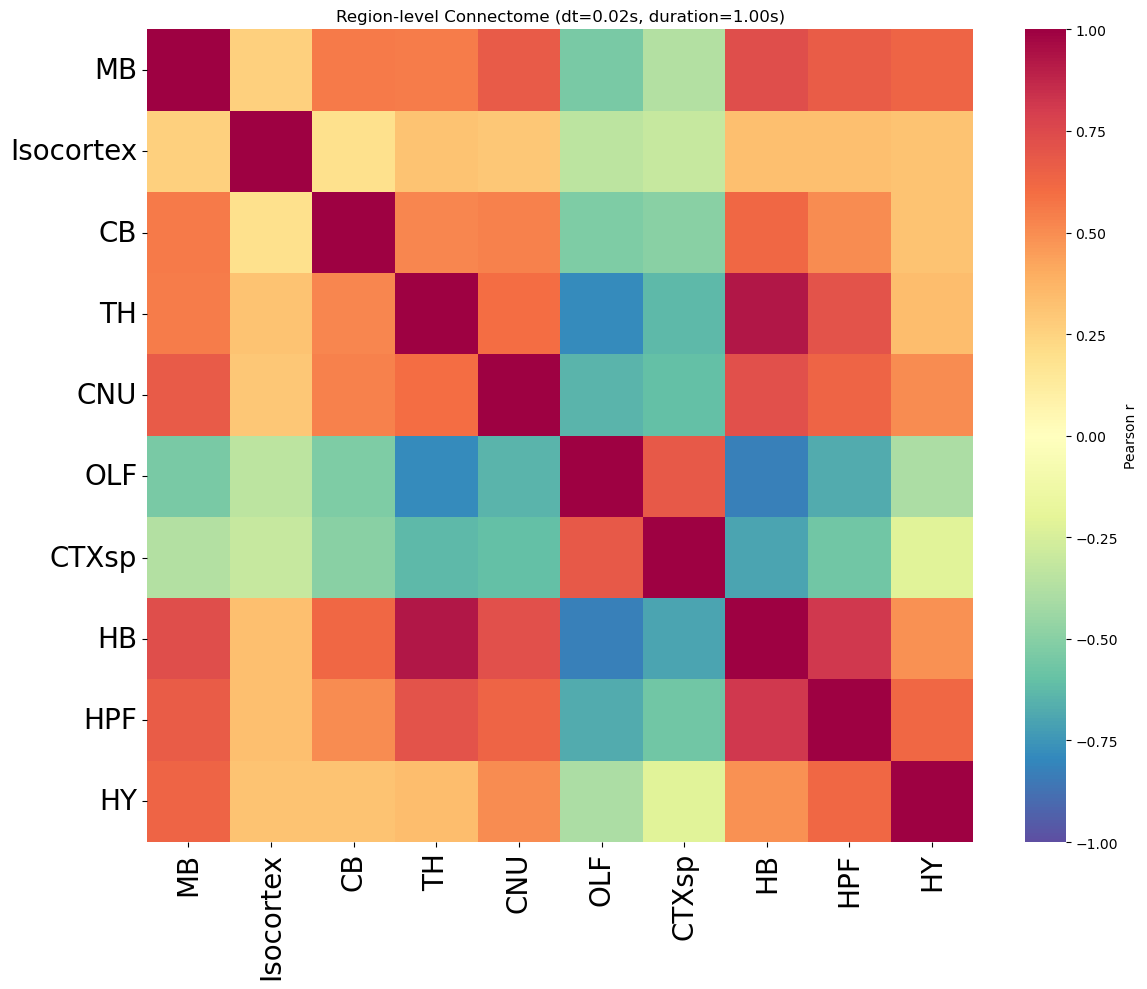

✅ Connectome 已保存到: result/fig/region_connectome_10_feedback-intervals1.png


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from iblatlas.regions import BrainRegions

os.makedirs("result/fig", exist_ok=True)

region_ids = sorted(binned_traces.keys())

region_matrix = np.array([binned_traces[rid] for rid in region_ids])

region_matrix = (region_matrix - region_matrix.mean(axis=1, keepdims=True)) / \
                 (region_matrix.std(axis=1, keepdims=True) + 1e-9)

corr_matrix = np.corrcoef(region_matrix)
corr_matrix_3 = corr_matrix
br = BrainRegions()
region_labels = [
    br.acronym[np.where(br.id == rid)[0][0]] if rid in br.id else str(rid)
    for rid in region_ids
]

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, 
            xticklabels=region_labels, 
            yticklabels=region_labels,
            cmap='Spectral_r', vmin=-1, vmax=1, cbar_kws={'label': 'Pearson r'})

plt.title(f"Region-level Connectome (dt=0.02s, duration={duration:.2f}s)")
plt.xticks(rotation=90, fontsize=20)
plt.yticks(rotation=0, fontsize=20)
plt.tight_layout()

out_path = "result/fig/region_connectome_10_feedback-intervals1.png"
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Connectome 已保存到: {out_path}")

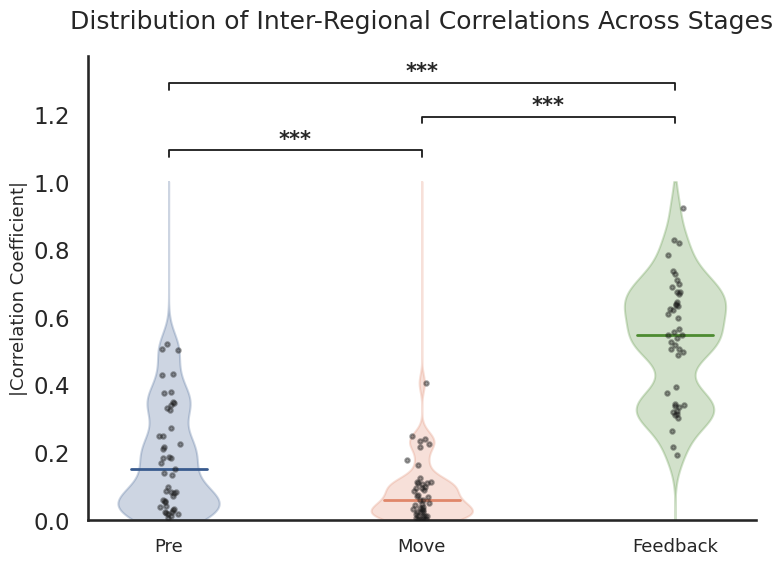

In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, gaussian_kde

def flatten_upper_abs(matrix):
    tri = np.triu_indices_from(matrix, k=1)
    return np.abs(matrix[tri])

vals1 = flatten_upper_abs(corr_matrix_1)
vals2 = flatten_upper_abs(corr_matrix_2)
vals3 = flatten_upper_abs(corr_matrix_3)

data_dict = {"Pre": vals1, "Move": vals2, "Feedback": vals3}
colors = ["#395B8E", "#E0876A", "#4D8B31"]

plt.figure(figsize=(8,6))
sns.set_theme(style="white", context="talk")

for i, (stage, vals) in enumerate(data_dict.items()):
    kde = gaussian_kde(vals, bw_method=0.3)
    y_grid = np.linspace(0, 1, 400)
    pdf = kde(y_grid)
    pdf = pdf / pdf.max() * 0.4
    plt.fill_betweenx(y_grid, i - pdf/2, i + pdf/2, color=colors[i], alpha=0.25)
    plt.plot([i-0.15, i+0.15], [np.median(vals), np.median(vals)],
             color=colors[i], lw=2)
    jitter = np.random.normal(0, 0.02, len(vals))
    plt.scatter(np.full_like(vals, i)+jitter, vals, s=10, color='k', alpha=0.4, zorder=5)

t12, p12 = ttest_ind(vals1, vals2, equal_var=False)
t23, p23 = ttest_ind(vals2, vals3, equal_var=False)
t13, p13 = ttest_ind(vals1, vals3, equal_var=False)
def p2star(p): return '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else 'ns'

ymax_data = max(np.max(vals1), np.max(vals2), np.max(vals3))
top_margin = 0.15
line_spacing = 0.1  
num_pairs = 3
ymax = ymax_data + top_margin + num_pairs*line_spacing
plt.ylim(0, ymax)

pairs = [(0,1,p12), (1,2,p23), (0,2,p13)]
for idx, (x1,x2,p) in enumerate(pairs):
    y_base = ymax_data + top_margin + idx*line_spacing
    plt.plot([x1, x1, x2, x2], [y_base, y_base+0.02, y_base+0.02, y_base], lw=1.3, c='k')
    plt.text((x1+x2)/2, y_base+0.025, p2star(p),
             ha='center', va='bottom', fontsize=15, fontweight='bold')

plt.xticks(range(3), list(data_dict.keys()), fontsize=13)
plt.ylabel('|Correlation Coefficient|', fontsize=13)
plt.title('Distribution of Inter-Regional Correlations Across Stages', pad=20)
sns.despine(right=True, top=True)
plt.tight_layout()
plt.show()

### 

## 3. SC

In [115]:
df_layers = pd.read_excel('SEU_net_w_corticalLayers.xlsx', header=1, index_col=1)
df_layers = df_layers.iloc[:, 1:]
df_layers

,FRP2/3,MOp1,MOp2/3,MOp5,MOp6a,MOs1,MOs2/3,MOs5,MOs6a,SSp-n2/3,...,MD,SMT,PVT,RE,CM,RT,PSV,PB,TRN,PRNr
FRP2/3,0.000000,0.0,0.000000,0.000000,0.000000,0.835160,2.300365,1.791165,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000
MOp1,0.000000,0.0,1.435472,2.390881,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000
MOp2/3,0.625221,0.0,2.078293,2.099848,1.924731,0.715541,1.498042,1.575019,0.0,0.426072,...,0.000000,0.00000,0.0,0.000000,0.0,0.932975,0,0,0,0.875238
MOp5,0.000000,0.0,1.068048,3.553463,1.668447,0.409365,2.183911,2.279111,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.794181,0,0,0,0.000000
MOp6a,0.000000,0.0,2.304936,0.488099,2.354786,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.917643,0,0,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,1.514522,2.13142,0.0,4.582369,0.0,0.762490,0,0,0,0.000000
PSV,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.000000,0,0,0,0.720976
PB,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.000000,0,0,0,1.214098
TRN,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.00000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000


In [118]:
df_nolayers = pd.read_excel('SEU_net_wo_corticalLayers.xlsx', header=1, index_col=1)
df_nolayers = df_nolayers.iloc[:, 1:]
df_nolayers

,FRP,MOp,MOs,SSp-n,SSp-bfd,SSp-ll,SSp-m,SSp-ul,SSp-tr,SSp-un,...,MD,SMT,PVT,RE,CM,RT,PSV,PB,TRN,PRNr
FRP,0.000000,0.000000,2.028292,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000
MOp,0.625221,1.992551,1.765525,0.930700,0.678581,1.968629,1.024268,0.953173,1.600363,0.961477,...,0.000000,0.000000,0.0,0.000000,0.0,0.861023,0,0,0,0.875238
MOs,1.417198,1.381516,1.645074,0.670320,2.725806,0.853611,1.209884,1.446972,0.000000,0.000000,...,0.000000,1.621683,0.0,0.000000,0.0,0.768877,0,0,0,0.000000
SSp-n,0.000000,0.789537,1.283165,1.795210,1.301726,0.000000,1.947067,2.399795,0.000000,1.158404,...,0.000000,0.000000,0.0,0.000000,0.0,0.810396,0,0,0,0.000000
SSp-bfd,0.000000,1.159698,0.766737,1.669994,1.934520,0.447926,1.166723,0.869816,3.467967,1.047941,...,0.000000,0.000000,0.0,0.000000,0.0,0.191446,0,0,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.514522,2.131420,0.0,4.582369,0.0,0.762490,0,0,0,0.000000
PSV,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.720976
PB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,1.214098
TRN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000


In [119]:
from one.api import ONE
import pickle
from collections import defaultdict, deque
import numpy as np
import pandas as pd

one = ONE()

with open('eid_to_trials.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)

region_table = region_table.copy()
region_table['parent'] = region_table['parent'].replace({None: np.nan})

id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
acronym_to_id = dict(zip(region_table['acronym'], region_table['atlas_id']))

# parent_id -> list(child_id)
children_map = defaultdict(list)
for _, row in region_table.iterrows():
    pid = row['parent']
    child_id = row['atlas_id']
    if not pd.isna(pid):
        children_map[int(pid)].append(int(child_id))

def get_descendant_acronyms(parent_acronym):

    if parent_acronym not in acronym_to_id:
        return []
    root_id = int(acronym_to_id[parent_acronym])
    descendants = []

    dq = deque([root_id])
    while dq:
        cur = dq.popleft()
        if cur in id_to_acronym:
            descendants.append(id_to_acronym[cur])
        for child in children_map.get(cur, []):
            dq.append(child)
    return descendants

target_parents = list(df_nolayers.index.astype(str).tolist())
all_target_acronyms = set()

missing_parents = []
for p in target_parents:
    desc = get_descendant_acronyms(p)
    if len(desc) == 0:
        missing_parents.append(p)
    else:
        all_target_acronyms.update(desc)

if missing_parents:
    for mp in missing_parents:
        print("  -", mp)


map_child_to_parent = {}
for parent in target_parents:
    for child in get_descendant_acronyms(parent):
        map_child_to_parent[child] = parent

brain_region_data = defaultdict(list)

for unit in all_units[:]:
    pid = unit['pid']
    cluster_id = unit['cluster_id']
    region_id = unit['atlas_id']

    if region_id not in region_table['atlas_id'].values:
        continue
    acronym = region_table.loc[region_table['atlas_id'] == region_id, 'acronym'].values[0]

    if acronym not in all_target_acronyms:
        continue

    matched = unit_df[(unit_df['pid'] == pid) & (unit_df['cluster_id'] == cluster_id)]
    if matched.empty:
        continue
    eid = matched['eid'].values[0]

    trials = eid_to_trials.get(eid, [])
    if len(trials) == 0:
        continue

    for trial_start, trial_end in trials:
        spike_mask = (unit['spike_times'] >= trial_start) & (unit['spike_times'] <= trial_end)
        if np.sum(spike_mask) == 0:
            continue

        spike_times_rel = unit['spike_times'][spike_mask] - trial_start
        spike_times_std = spike_times_rel / (trial_end - trial_start)
        spike_voltages = unit['spike_voltage'][spike_mask]

        parent_key = map_child_to_parent.get(acronym, acronym)  
        brain_region_data[parent_key].append({
            'spike_times': spike_times_std,
            'spike_voltages': spike_voltages
        })

brain_region_avg_voltage = {}
for region_name, units in brain_region_data.items():
    all_times = np.concatenate([u['spike_times'] for u in units])
    all_voltages = np.concatenate([u['spike_voltages'] for u in units])

    sort_idx = np.argsort(all_times)
    all_times_sorted = all_times[sort_idx]
    all_voltages_sorted = all_voltages[sort_idx]

    brain_region_avg_voltage[region_name] = {
        'spike_times': all_times_sorted,
        'spike_voltages': all_voltages_sorted
    }


with open('brain_region_wo_layer_stage1.pkl', 'wb') as f:
    pickle.dump(brain_region_avg_voltage, f)

In [120]:
from one.api import ONE
import pickle
from collections import defaultdict, deque
import numpy as np
import pandas as pd


one = ONE()

with open('eid_to_trials_firstMovement2response.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)


region_table = region_table.copy()
region_table['parent'] = region_table['parent'].replace({None: np.nan})

id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
acronym_to_id = dict(zip(region_table['acronym'], region_table['atlas_id']))

children_map = defaultdict(list)
for _, row in region_table.iterrows():
    pid = row['parent']
    child_id = row['atlas_id']
    if not pd.isna(pid):
        children_map[int(pid)].append(int(child_id))

def get_descendant_acronyms(parent_acronym):
    if parent_acronym not in acronym_to_id:
        return []
    root_id = int(acronym_to_id[parent_acronym])
    descendants = []
    dq = deque([root_id])
    while dq:
        cur = dq.popleft()
        if cur in id_to_acronym:
            descendants.append(id_to_acronym[cur])
        for child in children_map.get(cur, []):
            dq.append(child)
    return descendants


target_parents = list(df_nolayers.index.astype(str).tolist())
all_target_acronyms = set()

missing_parents = []
for p in target_parents:
    desc = get_descendant_acronyms(p)
    if len(desc) == 0:
        missing_parents.append(p)
    else:
        all_target_acronyms.update(desc)

if missing_parents:
    for mp in missing_parents:
        print("  -", mp)


map_child_to_parent = {}
for parent in target_parents:
    for child in get_descendant_acronyms(parent):
        map_child_to_parent[child] = parent

brain_region_data = defaultdict(list)

for unit in all_units[:]:
    pid = unit['pid']
    cluster_id = unit['cluster_id']
    region_id = unit['atlas_id']

    if region_id not in region_table['atlas_id'].values:
        continue
    acronym = region_table.loc[region_table['atlas_id'] == region_id, 'acronym'].values[0]

    if acronym not in all_target_acronyms:
        continue

    matched = unit_df[(unit_df['pid'] == pid) & (unit_df['cluster_id'] == cluster_id)]
    if matched.empty:
        continue
    eid = matched['eid'].values[0]

    trials = eid_to_trials.get(eid, [])
    if len(trials) == 0:
        continue

    for trial_start, trial_end in trials:
        spike_mask = (unit['spike_times'] >= trial_start) & (unit['spike_times'] <= trial_end)
        if np.sum(spike_mask) == 0:
            continue

        spike_times_rel = unit['spike_times'][spike_mask] - trial_start
        spike_times_std = spike_times_rel / (trial_end - trial_start)
        spike_voltages = unit['spike_voltage'][spike_mask]

        parent_key = map_child_to_parent.get(acronym, acronym)  
        brain_region_data[parent_key].append({
            'spike_times': spike_times_std,
            'spike_voltages': spike_voltages
        })


brain_region_avg_voltage = {}
for region_name, units in brain_region_data.items():
    all_times = np.concatenate([u['spike_times'] for u in units])
    all_voltages = np.concatenate([u['spike_voltages'] for u in units])

    sort_idx = np.argsort(all_times)
    all_times_sorted = all_times[sort_idx]
    all_voltages_sorted = all_voltages[sort_idx]

    brain_region_avg_voltage[region_name] = {
        'spike_times': all_times_sorted,
        'spike_voltages': all_voltages_sorted
    }


with open('brain_region_wo_layer_stage2.pkl', 'wb') as f:
    pickle.dump(brain_region_avg_voltage, f)

In [121]:
from one.api import ONE
import pickle
from collections import defaultdict, deque
import numpy as np
import pandas as pd

one = ONE()

with open('eid_to_trials_feedback2intervals1.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)


region_table = region_table.copy()
region_table['parent'] = region_table['parent'].replace({None: np.nan})

id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
acronym_to_id = dict(zip(region_table['acronym'], region_table['atlas_id']))

# parent_id -> list(child_id)
children_map = defaultdict(list)
for _, row in region_table.iterrows():
    pid = row['parent']
    child_id = row['atlas_id']
    if not pd.isna(pid):
        children_map[int(pid)].append(int(child_id))

def get_descendant_acronyms(parent_acronym):

    if parent_acronym not in acronym_to_id:
        return []
    root_id = int(acronym_to_id[parent_acronym])
    descendants = []
    dq = deque([root_id])
    while dq:
        cur = dq.popleft()
        if cur in id_to_acronym:
            descendants.append(id_to_acronym[cur])
        for child in children_map.get(cur, []):
            dq.append(child)
    return descendants

target_parents = list(df_nolayers.index.astype(str).tolist())
all_target_acronyms = set()

missing_parents = []
for p in target_parents:
    desc = get_descendant_acronyms(p)
    if len(desc) == 0:
        missing_parents.append(p)
    else:
        all_target_acronyms.update(desc)

if missing_parents:
    for mp in missing_parents:
        print("  -", mp)


map_child_to_parent = {}
for parent in target_parents:
    for child in get_descendant_acronyms(parent):
        map_child_to_parent[child] = parent

brain_region_data = defaultdict(list)

for unit in all_units[:]:
    pid = unit['pid']
    cluster_id = unit['cluster_id']
    region_id = unit['atlas_id']

    if region_id not in region_table['atlas_id'].values:
        continue
    acronym = region_table.loc[region_table['atlas_id'] == region_id, 'acronym'].values[0]

    if acronym not in all_target_acronyms:
        continue

    matched = unit_df[(unit_df['pid'] == pid) & (unit_df['cluster_id'] == cluster_id)]
    if matched.empty:
        continue
    eid = matched['eid'].values[0]

    trials = eid_to_trials.get(eid, [])
    if len(trials) == 0:
        continue

    for trial_start, trial_end in trials:
        spike_mask = (unit['spike_times'] >= trial_start) & (unit['spike_times'] <= trial_end)
        if np.sum(spike_mask) == 0:
            continue

        spike_times_rel = unit['spike_times'][spike_mask] - trial_start
        spike_times_std = spike_times_rel / (trial_end - trial_start)
        spike_voltages = unit['spike_voltage'][spike_mask]

        parent_key = map_child_to_parent.get(acronym, acronym)  
        brain_region_data[parent_key].append({
            'spike_times': spike_times_std,
            'spike_voltages': spike_voltages
        })

brain_region_avg_voltage = {}
for region_name, units in brain_region_data.items():
    all_times = np.concatenate([u['spike_times'] for u in units])
    all_voltages = np.concatenate([u['spike_voltages'] for u in units])

    sort_idx = np.argsort(all_times)
    all_times_sorted = all_times[sort_idx]
    all_voltages_sorted = all_voltages[sort_idx]

    brain_region_avg_voltage[region_name] = {
        'spike_times': all_times_sorted,
        'spike_voltages': all_voltages_sorted
    }


with open('brain_region_wo_layer_stage3.pkl', 'wb') as f:
    pickle.dump(brain_region_avg_voltage, f)


In [122]:
from one.api import ONE
import pickle
from collections import defaultdict, deque
import numpy as np
import pandas as pd

one = ONE()

with open('eid_to_trials.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)

region_table = region_table.copy()
region_table['parent'] = region_table['parent'].replace({None: np.nan})

id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
acronym_to_id = dict(zip(region_table['acronym'], region_table['atlas_id']))

# parent_id -> list(child_id)
children_map = defaultdict(list)
for _, row in region_table.iterrows():
    pid = row['parent']
    child_id = row['atlas_id']
    if not pd.isna(pid):
        children_map[int(pid)].append(int(child_id))

def get_descendant_acronyms(parent_acronym):

    if parent_acronym not in acronym_to_id:
        return []
    root_id = int(acronym_to_id[parent_acronym])
    descendants = []

    dq = deque([root_id])
    while dq:
        cur = dq.popleft()
        if cur in id_to_acronym:
            descendants.append(id_to_acronym[cur])
        for child in children_map.get(cur, []):
            dq.append(child)
    return descendants

target_parents = list(df_layers.index.astype(str).tolist())
all_target_acronyms = set()

missing_parents = []
for p in target_parents:
    desc = get_descendant_acronyms(p)
    if len(desc) == 0:
        missing_parents.append(p)
    else:
        all_target_acronyms.update(desc)

if missing_parents:
    for mp in missing_parents:
        print("  -", mp)


map_child_to_parent = {}
for parent in target_parents:
    for child in get_descendant_acronyms(parent):
        map_child_to_parent[child] = parent

brain_region_data = defaultdict(list)

for unit in all_units[:]:
    pid = unit['pid']
    cluster_id = unit['cluster_id']
    region_id = unit['atlas_id']

    if region_id not in region_table['atlas_id'].values:
        continue
    acronym = region_table.loc[region_table['atlas_id'] == region_id, 'acronym'].values[0]

    if acronym not in all_target_acronyms:
        continue

    matched = unit_df[(unit_df['pid'] == pid) & (unit_df['cluster_id'] == cluster_id)]
    if matched.empty:
        continue
    eid = matched['eid'].values[0]

    trials = eid_to_trials.get(eid, [])
    if len(trials) == 0:
        continue

    for trial_start, trial_end in trials:
        spike_mask = (unit['spike_times'] >= trial_start) & (unit['spike_times'] <= trial_end)
        if np.sum(spike_mask) == 0:
            continue

        spike_times_rel = unit['spike_times'][spike_mask] - trial_start
        spike_times_std = spike_times_rel / (trial_end - trial_start)
        spike_voltages = unit['spike_voltage'][spike_mask]

        parent_key = map_child_to_parent.get(acronym, acronym)  
        brain_region_data[parent_key].append({
            'spike_times': spike_times_std,
            'spike_voltages': spike_voltages
        })

brain_region_avg_voltage = {}
for region_name, units in brain_region_data.items():
    all_times = np.concatenate([u['spike_times'] for u in units])
    all_voltages = np.concatenate([u['spike_voltages'] for u in units])

    sort_idx = np.argsort(all_times)
    all_times_sorted = all_times[sort_idx]
    all_voltages_sorted = all_voltages[sort_idx]

    brain_region_avg_voltage[region_name] = {
        'spike_times': all_times_sorted,
        'spike_voltages': all_voltages_sorted
    }


with open('brain_region_w_layer_stage1.pkl', 'wb') as f:
    pickle.dump(brain_region_avg_voltage, f)

In [123]:
from one.api import ONE
import pickle
from collections import defaultdict, deque
import numpy as np
import pandas as pd

one = ONE()

with open('eid_to_trials_firstMovement2response.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)


region_table = region_table.copy()
region_table['parent'] = region_table['parent'].replace({None: np.nan})

id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
acronym_to_id = dict(zip(region_table['acronym'], region_table['atlas_id']))

children_map = defaultdict(list)
for _, row in region_table.iterrows():
    pid = row['parent']
    child_id = row['atlas_id']
    if not pd.isna(pid):
        children_map[int(pid)].append(int(child_id))

def get_descendant_acronyms(parent_acronym):
    if parent_acronym not in acronym_to_id:
        return []
    root_id = int(acronym_to_id[parent_acronym])
    descendants = []
    dq = deque([root_id])
    while dq:
        cur = dq.popleft()
        if cur in id_to_acronym:
            descendants.append(id_to_acronym[cur])
        for child in children_map.get(cur, []):
            dq.append(child)
    return descendants


target_parents = list(df_layers.index.astype(str).tolist())
all_target_acronyms = set()

missing_parents = []
for p in target_parents:
    desc = get_descendant_acronyms(p)
    if len(desc) == 0:
        missing_parents.append(p)
    else:
        all_target_acronyms.update(desc)

if missing_parents:
    for mp in missing_parents:
        print("  -", mp)


map_child_to_parent = {}
for parent in target_parents:
    for child in get_descendant_acronyms(parent):
        map_child_to_parent[child] = parent

brain_region_data = defaultdict(list)

for unit in all_units[:]:
    pid = unit['pid']
    cluster_id = unit['cluster_id']
    region_id = unit['atlas_id']

    if region_id not in region_table['atlas_id'].values:
        continue
    acronym = region_table.loc[region_table['atlas_id'] == region_id, 'acronym'].values[0]

    if acronym not in all_target_acronyms:
        continue

    matched = unit_df[(unit_df['pid'] == pid) & (unit_df['cluster_id'] == cluster_id)]
    if matched.empty:
        continue
    eid = matched['eid'].values[0]

    trials = eid_to_trials.get(eid, [])
    if len(trials) == 0:
        continue

    for trial_start, trial_end in trials:
        spike_mask = (unit['spike_times'] >= trial_start) & (unit['spike_times'] <= trial_end)
        if np.sum(spike_mask) == 0:
            continue

        spike_times_rel = unit['spike_times'][spike_mask] - trial_start
        spike_times_std = spike_times_rel / (trial_end - trial_start)
        spike_voltages = unit['spike_voltage'][spike_mask]

        parent_key = map_child_to_parent.get(acronym, acronym)  
        brain_region_data[parent_key].append({
            'spike_times': spike_times_std,
            'spike_voltages': spike_voltages
        })


brain_region_avg_voltage = {}
for region_name, units in brain_region_data.items():
    all_times = np.concatenate([u['spike_times'] for u in units])
    all_voltages = np.concatenate([u['spike_voltages'] for u in units])

    sort_idx = np.argsort(all_times)
    all_times_sorted = all_times[sort_idx]
    all_voltages_sorted = all_voltages[sort_idx]

    brain_region_avg_voltage[region_name] = {
        'spike_times': all_times_sorted,
        'spike_voltages': all_voltages_sorted
    }


with open('brain_region_w_layer_stage2.pkl', 'wb') as f:
    pickle.dump(brain_region_avg_voltage, f)


In [124]:
from one.api import ONE
import pickle
from collections import defaultdict, deque
import numpy as np
import pandas as pd

one = ONE()

with open('eid_to_trials_feedback2intervals1.pkl', 'rb') as f:
    eid_to_trials = pickle.load(f)


region_table = region_table.copy()
region_table['parent'] = region_table['parent'].replace({None: np.nan})

id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
acronym_to_id = dict(zip(region_table['acronym'], region_table['atlas_id']))

# parent_id -> list(child_id)
children_map = defaultdict(list)
for _, row in region_table.iterrows():
    pid = row['parent']
    child_id = row['atlas_id']
    if not pd.isna(pid):
        children_map[int(pid)].append(int(child_id))

def get_descendant_acronyms(parent_acronym):

    if parent_acronym not in acronym_to_id:
        return []
    root_id = int(acronym_to_id[parent_acronym])
    descendants = []
    dq = deque([root_id])
    while dq:
        cur = dq.popleft()
        if cur in id_to_acronym:
            descendants.append(id_to_acronym[cur])
        for child in children_map.get(cur, []):
            dq.append(child)
    return descendants

target_parents = list(df_layers.index.astype(str).tolist())
all_target_acronyms = set()

missing_parents = []
for p in target_parents:
    desc = get_descendant_acronyms(p)
    if len(desc) == 0:
        missing_parents.append(p)
    else:
        all_target_acronyms.update(desc)

if missing_parents:
    for mp in missing_parents:
        print("  -", mp)


map_child_to_parent = {}
for parent in target_parents:
    for child in get_descendant_acronyms(parent):
        map_child_to_parent[child] = parent

brain_region_data = defaultdict(list)

for unit in all_units[:]:
    pid = unit['pid']
    cluster_id = unit['cluster_id']
    region_id = unit['atlas_id']

    if region_id not in region_table['atlas_id'].values:
        continue
    acronym = region_table.loc[region_table['atlas_id'] == region_id, 'acronym'].values[0]

    if acronym not in all_target_acronyms:
        continue

    matched = unit_df[(unit_df['pid'] == pid) & (unit_df['cluster_id'] == cluster_id)]
    if matched.empty:
        continue
    eid = matched['eid'].values[0]

    trials = eid_to_trials.get(eid, [])
    if len(trials) == 0:
        continue

    for trial_start, trial_end in trials:
        spike_mask = (unit['spike_times'] >= trial_start) & (unit['spike_times'] <= trial_end)
        if np.sum(spike_mask) == 0:
            continue

        spike_times_rel = unit['spike_times'][spike_mask] - trial_start
        spike_times_std = spike_times_rel / (trial_end - trial_start)
        spike_voltages = unit['spike_voltage'][spike_mask]

        parent_key = map_child_to_parent.get(acronym, acronym)  
        brain_region_data[parent_key].append({
            'spike_times': spike_times_std,
            'spike_voltages': spike_voltages
        })

brain_region_avg_voltage = {}
for region_name, units in brain_region_data.items():
    all_times = np.concatenate([u['spike_times'] for u in units])
    all_voltages = np.concatenate([u['spike_voltages'] for u in units])

    sort_idx = np.argsort(all_times)
    all_times_sorted = all_times[sort_idx]
    all_voltages_sorted = all_voltages[sort_idx]

    brain_region_avg_voltage[region_name] = {
        'spike_times': all_times_sorted,
        'spike_voltages': all_voltages_sorted
    }


with open('brain_region_w_layer_stage3.pkl', 'wb') as f:
    pickle.dump(brain_region_avg_voltage, f)
